In [1]:
!pip install matplotlib datasets torch transformers evaluate

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 469.0/469.0 KB 7.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 23.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.4/81.4 KB 5.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.3/190.3 KB 8.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 213.0/213.0 KB 5.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.0/132.0 KB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.5/110.5 KB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 13.3 MB/s eta 0:00:00


In [2]:
import os
import random
import pandas as pd
from datasets import Dataset, Features, Value, ClassLabel
import collections
from collections import Counter
import matplotlib.pyplot as plt
from pathlib import Path
from datasets import DatasetDict
import evaluate
import torch
import numpy as np
from transformers import pipeline
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
#test_set 
test_set = [os.path.join("classifier-dataset/dataset/test_set", f) for f in os.listdir("classifier-dataset/dataset/test_set")]
test_set = random.sample(test_set, len(test_set))
print("Test Set: " + str(len(test_set)))

Test Set: 1250


In [5]:
#making labels, read the category from the name of the file 
def make_labels(data):
    files = data
    file_list = []
    train_labels = [None] * (len(files))
    count = 0
    docID = 0
    for fil in files:
        file_list.append(fil)
        train_labels[docID] = 'non-relevant'
        filepathTokens = fil.split('/')
        lastToken = filepathTokens[len(filepathTokens) - 1]
        if fil.endswith("_clinical.txt"):
            train_labels[docID] = 'clinical'
            count = count + 1
        elif fil.endswith("_non-clinical.txt"):
            train_labels[docID] = 'non-clinical'
            count = count + 1
        docID = docID + 1
    combined_labels_files = dict(zip(train_labels, file_list))
    #print (train_labels)
    #print (file_list)
    print (combined_labels_files)
    return train_labels, file_list, combined_labels_files


test_set_labels, test_file_list, combined_testing  = make_labels(test_set)

df_test = pd.DataFrame(data={ 'label':test_set_labels,'files': test_set})


{'clinical': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set/23676632_clinical.txt', 'non-relevant': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set/21092508_background.txt', 'non-clinical': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set/20919949_non-clinical.txt'}


Counter({'non-relevant': 641, 'non-clinical': 361, 'clinical': 248})
OrderedDict([('clinical', 248), ('non-clinical', 361), ('non-relevant', 641)])
[248, 361, 641]


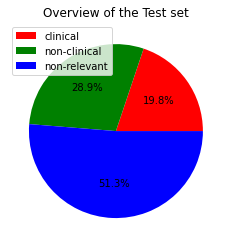

In [6]:
# to represent the distribution of the test:
labels = ['clinical','non-clinical','non-relevant']
sizes = Counter(test_set_labels)
print (sizes)
sizes = collections.OrderedDict(sorted(sizes.items()))
print (sizes)
sizes = list((sizes).values())
print (sizes)
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the Test set')
plt.show()

In [7]:
X_test_text = [Path(file).read_text() for file in test_set]

In [8]:
df_test['text'] = X_test_text
df_test=df_test[["label", "text"]]

In [10]:
debbie_class_names = ["clinical", "non-clinical","non-relevant"]
debbie_features = Features({'text': Value('string'), 'label': ClassLabel(names=debbie_class_names)})
dataset_test = Dataset.from_pandas(df_test, features=debbie_features)
dataset_test

Dataset({
    features: ['text', 'label'],
    num_rows: 1250
})

In [11]:
dataset_test[0]

{'text': 'A prospective 9-month human clinical evaluation of Laser-Assisted New Attachment Procedure (LANAP) therapy.\nThis investigation was designed and implemented as a single-center, prospective study to evaluate the clinical response to the Laser-Assisted New Attachment Procedure (LANAP). Eight patients with advanced periodontitis were enrolled and treated with full-mouth LANAP therapy and monitored for 9 months. Fullmouth clinical measurements, including clinical attachment level (CAL), probing depth (PD), and recession, were provided at baseline and after 9 months of healing by a single calibrated examiner, including a total of 930 sites and 444 sites with initial PD equal to or greater than 5 mm. Clinical results for the 930 sites measured pre- and postoperatively revealed that mean PD was reduced from 4.62 ± 2.29 mm to 3.14 ± 1.48 mm after 9 months (P < .05). CAL decreased from 5.58 ± 2.76 mm to 4.66 ± 2.10 mm (P < .05) and recession increased from 0.86 ± 1.31 mm to 1.52 ± 1.6

In [12]:
dataset_test.features

{'text': Value(dtype='string', id=None),
 'label': ClassLabel(names=['clinical', 'non-clinical', 'non-relevant'], id=None)}

In [41]:
#DEBBIE model
checkpoint = "javicorvi/DEBBIE_BioBERT"

In [43]:
pipe = pipeline("text-classification", model=checkpoint) 


In [44]:
y_predict = pipe(X_test_text, padding=True, truncation=True)

In [45]:
labels_y = [d.get('label') for d in y_predict]


In [46]:
y_true = test_set_labels
labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=y_true, y_pred=labels_y,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(y_true, labels_y)
print('Confusion Matrix:',conf_matrix)

              precision    recall  f1-score   support

    clinical       0.76      0.91      0.83       248
non-clinical       0.96      0.96      0.96       361
non-relevant       0.96      0.88      0.92       641

    accuracy                           0.91      1250
   macro avg       0.89      0.92      0.90      1250
weighted avg       0.92      0.91      0.91      1250

Confusion Matrix: [[226   3  19]
 [  7 348   6]
 [ 65  12 564]]


<AxesSubplot:>

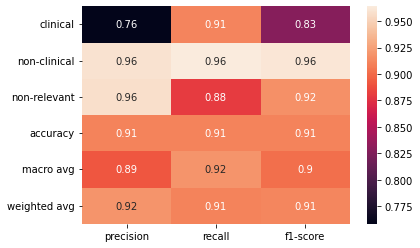

In [47]:
clf_report = classification_report(y_true=y_true, y_pred=labels_y,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)

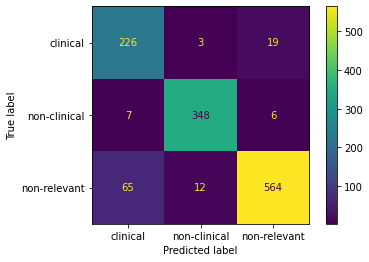

In [48]:
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()